# Figure 6

Redraws the panels of Fig. 6 from the source data.

The source data are deposited on figshare (https://doi.org/10.6084/m9.figshare.34601982): `Wilhelm_SourceData.xlsx` (one worksheet per panel), per-point `Wilhelm_SourceData_*.parquet` files and summary `Wilhelm_SourceData_*.csv` files; `README.md` of the deposit describes all columns. `source_data.py` downloads the files into `./data` on first use. Set `FIGSHARE_ARTICLE_ID` in the next cell (or as environment variable; `FIGSHARE_TOKEN` while the article is private), or point `SOURCE_DATA_DIR` to a local copy of the files.

* a: `Wilhelm_SourceData_Fig6a.parquet` (Delta mass per open-search PSM), `Wilhelm_SourceData_Fig6a_pies.csv` (pie slices), `Wilhelm_SourceData_Fig6a_parameters.csv` (filter counts and density parameters)
* b, c: worksheets `Fig6b`, `Fig6c` (mirror spectra; spectral angles in table `Fig6b_c_summary`)
* d: `Wilhelm_SourceData_Fig6d.parquet` and `Wilhelm_SourceData_Fig6d_summary.csv`
* e, f: `Wilhelm_SourceData_Fig6e_f.parquet` and `Wilhelm_SourceData_Fig6e_f_summary.csv`
* g: worksheet `Fig6g`


In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
import seaborn as sns
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'Fig6'
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(name):
    for ext in ('pdf', 'png'):
        plt.savefig(FIG_DIR / f'{name}.{ext}', dpi=300, bbox_inches='tight')


readme('Fig6')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Fig. 6,a,NaN,Wilhelm_SourceData_Fig6a.parquet; Wilhelm_Sour...,Delta mass of each open-search PSM in the dens...,NaN
1,Fig. 6,b,Fig6b,NaN,"Predicted fragment ions (Prosit-22PTM, HCD, NC...",Fig6b; Fig6b_c_summary
2,Fig. 6,c,Fig6c,NaN,Experimental spectrum HF181130_PIC_A scan 1544...,Fig6c_experimental; Fig6c_predicted
3,Fig. 6,d,NaN,Wilhelm_SourceData_Fig6d.parquet; Wilhelm_Sour...,Spectral angle of each PSM under the acetylati...,NaN
4,Fig. 6,e,NaN,Wilhelm_SourceData_Fig6e_f.parquet; Wilhelm_So...,Spectral angle of each PSM on synthetic acetyl...,NaN
5,Fig. 6,f,NaN,Wilhelm_SourceData_Fig6e_f.parquet,Spectral angle of each PSM on synthetic guanid...,NaN
6,Fig. 6,g,Fig6g,NaN,Number and percentage of PSMs per open-search ...,Fig6g


## Panel a — open-search Delta mass distribution and modification pie charts

Delta mass of the MSFragger open-search target PSMs of the histone samples (PXD024745; D3 PRO, PRO2, PIC) between -10 and 130 Da. Gaussian kernel density (`scipy.stats.gaussian_kde`, `bw_method=0.012`, i.e. 0.357 Da) evaluated on 2,000 points from -10 to 130 Da and multiplied by the number of PSMs (y = PSMs per Da). Red lines: Delta-mass labels of the pie-chart windows; pie slices per window from `Wilhelm_SourceData_Fig6a_pies.csv` (grey = remainder to 100 %).

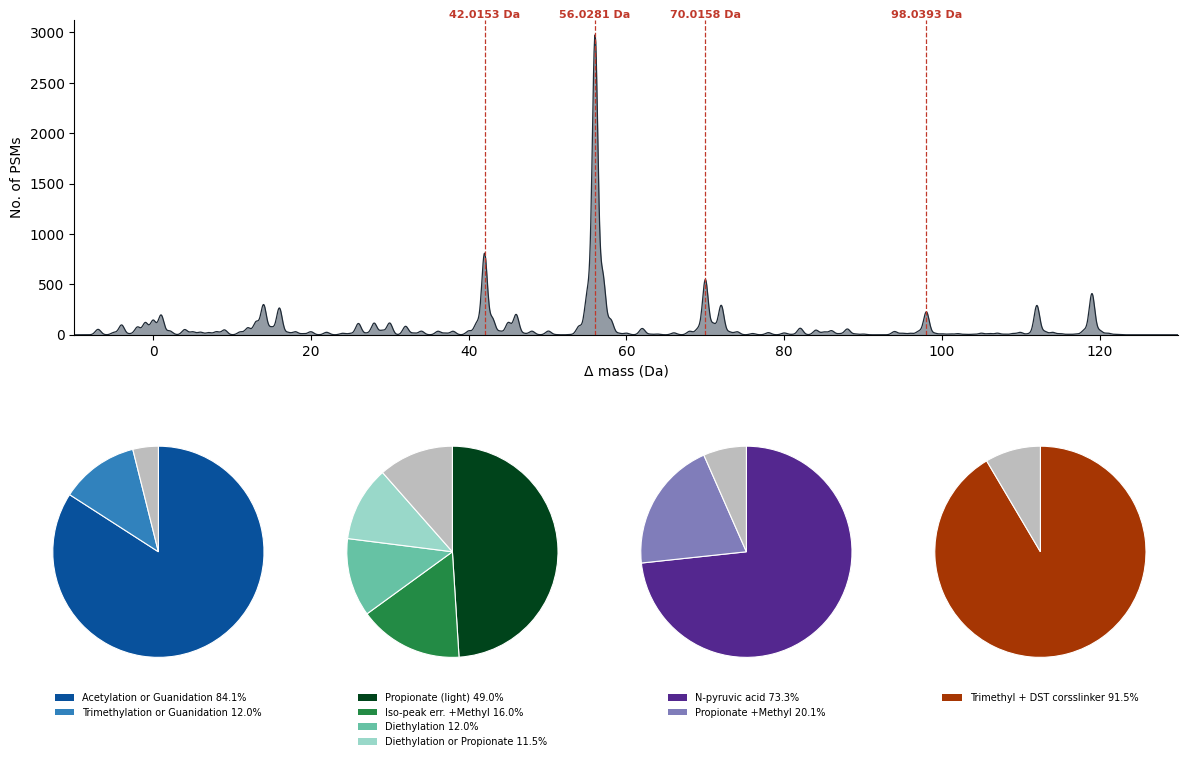

,window (Da),delta_mass_label (Da),slice_label,slice_percent (%)
0,42-42.1,42.0153,Acetylation or Guanidation,84.1
1,42-42.1,42.0153,Trimethylation or Guanidation,12.0
2,42-42.1,42.0153,"(grey, unlabelled)",3.9
3,56-56.1,56.0281,Propionate (light),49.0
4,56-56.1,56.0281,Iso-peak err. +Methyl,16.0
5,56-56.1,56.0281,Diethylation,12.0
6,56-56.1,56.0281,Diethylation or Propionate,11.5
7,56-56.1,56.0281,"(grey, unlabelled)",11.5
8,70-70.1,70.0158,N-pyruvic acid,73.3
9,70-70.1,70.0158,Propionate +Methyl,20.1


In [3]:
a = pd.read_parquet(fetch('Wilhelm_SourceData_Fig6a.parquet'))
pies = table('Fig6a_pies')
dm = a['delta_mass (Da)'].to_numpy()
kde = gaussian_kde(dm, bw_method=0.012)
grid = np.linspace(-10, 130, 2000)
y = kde(grid) * len(dm)

windows = list(dict.fromkeys(pies['window (Da)']))
PAL = [['#08519c', '#3182bd', '#6baed6'], ['#00441b', '#238b45', '#66c2a4', '#99d8c9'], ['#54278f', '#807dba'], ['#a63603']]
fig = plt.figure(figsize=(12, 7))
ax = fig.add_axes([0.06, 0.52, 0.92, 0.45])
ax.fill_between(grid, 0, y, color='#3a4a59', alpha=0.55, lw=0)
ax.plot(grid, y, color='#1f2a36', lw=0.9)
for w in windows:
    lab = pies.loc[pies['window (Da)'] == w, 'delta_mass_label (Da)'].iloc[0]
    ax.axvline(lab, color='#c0392b', ls='--', lw=0.9)
    ax.text(lab, 1.0, f'{lab:.4f} Da', transform=ax.get_xaxis_transform(), color='#c0392b', fontweight='bold',
            ha='center', va='bottom', fontsize=8)
ax.set_xlim(-10, 130)
ax.set_ylim(0, None)
ax.set_xlabel('Δ mass (Da)')
ax.set_ylabel('No. of PSMs')
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
for i, w in enumerate(windows):
    p = pies[pies['window (Da)'] == w]
    pax = fig.add_axes([0.02 + i * 0.245, 0.0, 0.22, 0.42])
    cols = [('#bdbdbd' if l.startswith('(grey') else PAL[i][min(k, len(PAL[i]) - 1)])
            for k, l in enumerate(p['slice_label'])]
    pax.pie(p['slice_percent (%)'], colors=cols, startangle=90, counterclock=False,
            wedgeprops=dict(edgecolor='white', linewidth=0.8))
    shown = ~p['slice_label'].str.startswith('(grey')
    texts = [f"{l} {v:.1f}%" for l, v in zip(p.loc[shown, 'slice_label'], p.loc[shown, 'slice_percent (%)'])]
    pax.legend([plt.Rectangle((0, 0), 1, 1, fc=c) for c, k in zip(cols, shown) if k], texts,
               loc='upper center', bbox_to_anchor=(0.5, 0.0), fontsize=7, frameon=False)
save('Fig6a')
plt.show()
pies

## Panels b, c — mirror spectra

b: Prosit-22PTM predicted fragment ions (HCD, NCE 37) of EIAQDFK(acetyl)TDLR (top) and EIAQDFK(guanidinyl)TDLR (bottom), 2+; peaks > 4 % relative intensity drawn. c: experimental spectrum HF181130_PIC_A scan 15442 (top; intensity relative to the most intense annotated b/y ion) and the predicted acetylation spectrum (bottom). Spectral angles from table `Fig6b_c_summary`.

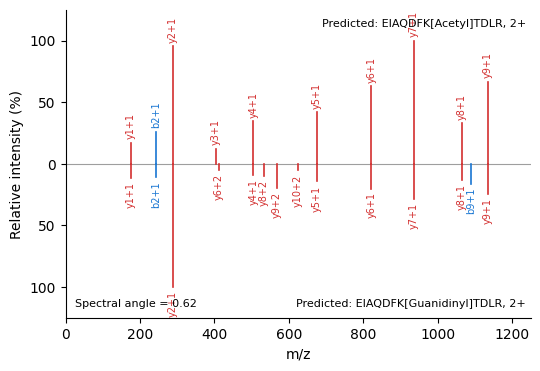

,ion,ion_type,ion_number,fragment_charge,m/z acetylation (Th),predicted_relative_intensity acetylation (%),m/z guanidination (Th),predicted_relative_intensity guanidination (%),drawn acetylation (> 4 %),drawn guanidination (> 4 %)
0,y1+1,y,1,1,175.11896,16.936,175.11896,11.356,True,True
1,y1+2,y,1,2,88.06312,0.000,88.06312,0.000,False,False
2,b1+1,b,1,1,130.04987,0.000,130.04987,0.000,False,False
3,b1+2,b,1,2,65.52857,0.000,65.52857,0.000,False,False
4,y2+1,y,2,1,288.20300,95.597,288.20300,100.000,True,True
5,y2+2,y,2,2,144.60515,0.000,144.60515,0.000,False,False
6,b2+1,b,2,1,243.13393,26.141,243.13393,10.887,True,True
7,b2+2,b,2,2,122.07060,0.000,122.07060,0.000,False,False
8,y3+1,y,3,1,403.22995,12.291,403.22995,2.455,True,False
9,y3+2,y,3,2,202.11862,0.000,202.11862,0.000,False,False


In [4]:
b = table('Fig6b')
sa = table('Fig6b_c_summary').set_index('panel')['spectral_angle (0-1)']
COL = {'y': '#D32F2F', 'b': '#1976D2', '': '#212121'}


def sticks(ax, mz, inten, types, labels, sign):
    for m, i, t, l in zip(mz, inten, types, labels):
        ax.plot([m, m], [0, sign * i], color=COL[t], lw=1.2 if t else 0.8, zorder=3 if t else 2)
        if l:
            ax.text(m, sign * (i + 3), l, rotation=90, color=COL[t], fontsize=7,
                    ha='center', va='bottom' if sign > 0 else 'top')


def style(ax, title_top, title_bottom, sa_val):
    ax.axhline(0, color='#9E9E9E', lw=0.8)
    ax.set_xlim(0, 1250)
    ax.set_ylim(-125, 125)
    ax.set_yticks([-100, -50, 0, 50, 100], ['100', '50', '0', '50', '100'])
    ax.set_xlabel('m/z')
    ax.set_ylabel('Relative intensity (%)')
    ax.text(0.99, 0.97, title_top, transform=ax.transAxes, ha='right', va='top', fontsize=8)
    ax.text(0.99, 0.03, title_bottom, transform=ax.transAxes, ha='right', va='bottom', fontsize=8)
    ax.text(0.02, 0.03, f'Spectral angle = {sa_val:.2f}', transform=ax.transAxes, ha='left', va='bottom', fontsize=8)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)


fig, ax = plt.subplots(figsize=(6, 4))
t = b[b['drawn acetylation (> 4 %)']]
sticks(ax, t['m/z acetylation (Th)'], t['predicted_relative_intensity acetylation (%)'], t['ion_type'], t['ion'], 1)
t = b[b['drawn guanidination (> 4 %)']]
sticks(ax, t['m/z guanidination (Th)'], t['predicted_relative_intensity guanidination (%)'], t['ion_type'], t['ion'], -1)
style(ax, 'Predicted: EIAQDFK[Acetyl]TDLR, 2+', 'Predicted: EIAQDFK[Guanidinyl]TDLR, 2+', sa['Fig6b'])
save('Fig6b')
plt.show()
b

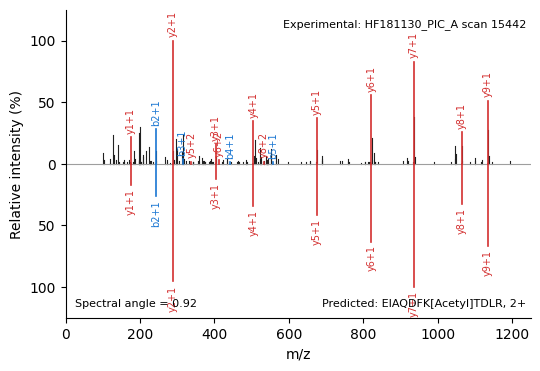

In [5]:
ce = table('Fig6c_experimental').fillna({'annotation (b/y, z <= 2, 30 ppm)': ''})
ce = ce[ce['drawn_in_figure'].astype(bool)]  # peaks drawn in panel c
cp = table('Fig6c_predicted')
fig, ax = plt.subplots(figsize=(6, 4))
lab = ce['annotation (b/y, z <= 2, 30 ppm)']
sticks(ax, ce['m/z (Th)'], ce['relative_intensity (% of most intense annotated b/y ion)'], lab.str[0].fillna(''), lab, 1)
t = cp[cp['drawn acetylation (> 4 %)']]
sticks(ax, t['m/z acetylation (Th)'], t['predicted_relative_intensity acetylation (%)'], t['ion_type'], t['ion'], -1)
style(ax, 'Experimental: HF181130_PIC_A scan 15442', 'Predicted: EIAQDFK[Acetyl]TDLR, 2+', sa['Fig6c'])
save('Fig6c')
plt.show()

## Panel d — acetylation vs guanidination spectral angle

Open-search PSMs identified (after rescoring, 1% FDR) as lysine acetylation or guanidination for which the guanidination hypothesis annotates at least as many fragment ions as the acetylation hypothesis: spectral angle of the same spectrum against the Prosit-22PTM prediction of each hypothesis, coloured by the identified modification. n per class from the data, medians from `Wilhelm_SourceData_Fig6d_summary.csv`.

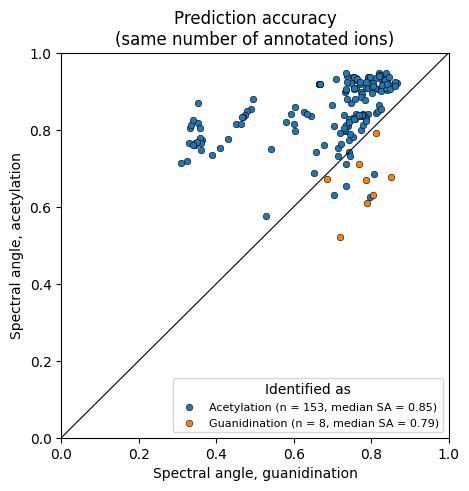

,identified_as,n_PSMs,median_SA_of_identified_modification (0-1)
0,Acetylation,153,0.85
1,Guanidination,8,0.79


In [6]:
d = pd.read_parquet(fetch('Wilhelm_SourceData_Fig6d.parquet'))
med = table('Fig6d_summary').set_index('identified_as')['median_SA_of_identified_modification (0-1)']
fig, ax = plt.subplots(figsize=(5, 5))
for cls, colr, sac in [('Acetylation', '#1f77b4', 'spectral_angle acetylation (0-1)'),
                       ('Guanidination', '#ff7f0e', 'spectral_angle guanidination (0-1)')]:
    g = d[d['identified_as (open search + rescoring, 1% FDR)'] == cls]
    ax.scatter(g['spectral_angle guanidination (0-1)'], g['spectral_angle acetylation (0-1)'], s=22, color=colr,
               edgecolor='k', lw=0.4, label=f'{cls} (n = {len(g)}, median SA = {med[cls]:.2f})')
ax.plot([0, 1], [0, 1], 'k-', lw=0.8)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel('Spectral angle, guanidination')
ax.set_ylabel('Spectral angle, acetylation')
ax.set_title('Prediction accuracy\n(same number of annotated ions)')
ax.legend(title='Identified as', loc='lower right', fontsize=8)
save('Fig6d')
plt.show()
table('Fig6d_summary')

## Panels e, f — spectral angle on synthetic acetylated / guanidinated peptides

Spectral angle of each PSM (synthetic JPT peptides, Oktoberfest rescoring with Prosit_2025_intensity_22PTM, 1% FDR) per precursor charge; e: acetylated peptides (rescoring spectral angle), f: guanidinated peptides (spectral angle at the per-PSM calibrated collision energy and fragmentation). Violins: seaborn `violinplot`, Scott bandwidth x 1.5 (`bw_adjust=1.5`), default `cut=2`; red line and label = median, n = number of PSMs per charge.

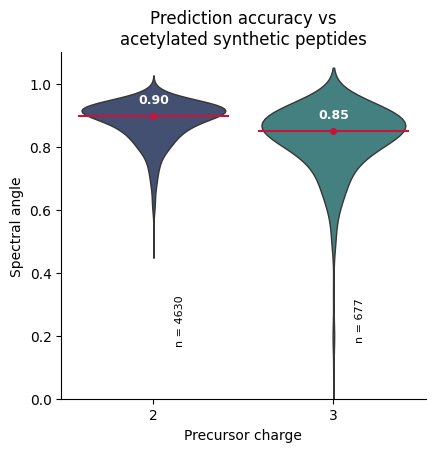

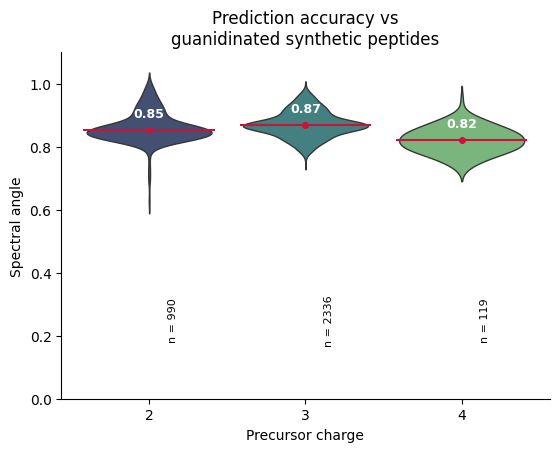

,panel,precursor_charge,n_PSMs,median_spectral_angle (0-1)
0,Fig6e,2,4630,0.8975
1,Fig6e,3,677,0.8499
2,Fig6f,2,990,0.8530
3,Fig6f,3,2336,0.8691
4,Fig6f,4,119,0.8215


In [7]:
def violin(df, title, name):
    PAL = ['#3b4d7a', '#3a8a8a', '#6fbf73']
    charges = sorted(df['precursor_charge'].unique())
    data = [df.loc[df['precursor_charge'] == z, 'spectral_angle (0-1)'].values for z in charges]
    fig, ax = plt.subplots(figsize=(1.6 * len(charges) + 1.5, 4.5))
    sns.violinplot(data=df, x='precursor_charge', y='spectral_angle (0-1)', order=charges, hue='precursor_charge',
                   hue_order=charges, palette=PAL[:len(charges)], inner=None, linewidth=1.0, legend=False,
                   bw_adjust=1.5, ax=ax)
    for i, v in enumerate(data):
        m = np.median(v)
        ax.hlines(m, i - 0.42, i + 0.42, color='#c8133b', lw=1.5, zorder=3)
        ax.plot(i, m, 'o', color='#c8133b', ms=4, zorder=4)
        ax.text(i, m + 0.03, f'{m:.2f}', ha='center', va='bottom', color='white', fontsize=9, fontweight='bold')
        ax.text(i + 0.12, 0.25, f'n = {len(v)}', rotation=90, ha='left', va='center', fontsize=8)
    ax.set_xticks(range(len(charges)), charges)
    ax.set_ylim(0, 1.1)
    ax.set_xlabel('Precursor charge')
    ax.set_ylabel('Spectral angle')
    ax.set_title(title)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    save(name)
    plt.show()


ef = pd.read_parquet(fetch('Wilhelm_SourceData_Fig6e_f.parquet'))
violin(ef[ef['panel'] == 'Fig6e'], 'Prediction accuracy vs\nacetylated synthetic peptides', 'Fig6e')
violin(ef[ef['panel'] == 'Fig6f'], 'Prediction accuracy vs\nguanidinated synthetic peptides', 'Fig6f')
table('Fig6e_f_summary')

## Panel g — open-search rescoring groups

Number and percentage of PSMs per open-search rescoring group (1% FDR); groups aggregated by manual curation of the pairwise spectral-angle comparisons of competing modification assignments.

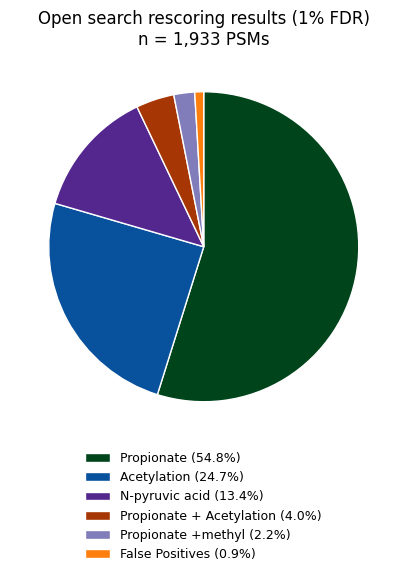

,group,n_PSMs,percent (%),aggregated from (manual curation)
0,Propionate,1060,54.8,Propionylation vs Diethylation (446) + Propion...
1,Acetylation,477,24.7,"Guanidination vs Acetylation comparison, PSMs ..."
2,N-pyruvic acid,259,13.4,"Propionyl+methyl vs N-pyruvic acid comparison,..."
3,Propionate + Acetylation,77,4.0,Propionyl+methyl+acetyl vs trimethyl+DST cross...
4,Propionate +methyl,42,2.2,"Propionyl+methyl vs N-pyruvic acid comparison,..."
5,False Positives,18,0.9,9 guanidination + 5 propionyl+methyl + 3 trime...


In [8]:
g = table('Fig6g')
COLS = ['#00441B', '#08519C', '#54278F', '#A63603', '#807DBA', '#ff7f0e']
fig, ax = plt.subplots(figsize=(5, 6))
w, _ = ax.pie(g['n_PSMs'], colors=COLS, startangle=90, counterclock=False, wedgeprops=dict(edgecolor='white', linewidth=1))
ax.legend(w, [f"{l} ({p:.1f}%)" for l, p in zip(g['group'], g['percent (%)'])],
          loc='upper center', bbox_to_anchor=(0.5, 0.0), frameon=False, fontsize=9)
ax.set_title(f"Open search rescoring results (1% FDR)\nn = {g['n_PSMs'].sum():,} PSMs")
ax.set_aspect('equal')
save('Fig6g')
plt.show()
g